# Lab06 Attention

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

tokens = ["The", "movie", "was", "surprisingly", "good", "despite", "a", "very", "slow", "beginning"]
d_k = 4

In [2]:
keys_dict = {
    "The":          [0.1,  0.0,  1.0,  0.1],
    "movie":        [0.2,  0.0,  0.1,  1.0],
    "was":          [0.0,  0.0,  1.0,  0.0],
    "surprisingly": [0.8,  0.3,  0.2,  0.1],
    "good":         [1.5,  0.1,  0.1,  0.2],
    "despite":      [0.0, -0.2,  0.8,  0.0],
    "a":            [0.0,  0.0,  1.0,  0.0],
    "very":         [0.5,  0.2,  0.5,  0.0],
    "slow":        [-0.4, -1.2,  0.1,  0.1],
    "beginning":    [0.1, -0.5,  0.2,  0.4]
}

In [3]:
K = np.array([keys_dict[t] for t in tokens])
q = np.array([1.2, 0.0, 0.0, 0.0])

scores = np.dot(K, q) / np.sqrt(d_k)  

In [4]:
def stable_softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

In [5]:
attention_weights = stable_softmax(scores)

exp1_df = pd.DataFrame({
    "Token": tokens,
    "Score": np.round(scores, 4),
    "Attention Weight": np.round(attention_weights, 4),
    "Percentage (%)": np.round(attention_weights * 100, 2)
})
display(exp1_df)

,Token,Score,Attention Weight,Percentage (%)
0,The,0.06,0.0852,8.52
1,movie,0.12,0.0905,9.05
2,was,0.00,0.0802,8.02
3,surprisingly,0.48,0.1297,12.97
4,good,0.90,0.1973,19.73
5,despite,0.00,0.0802,8.02
6,a,0.00,0.0802,8.02
7,very,0.30,0.1083,10.83
8,slow,-0.24,0.0631,6.31
9,beginning,0.06,0.0852,8.52


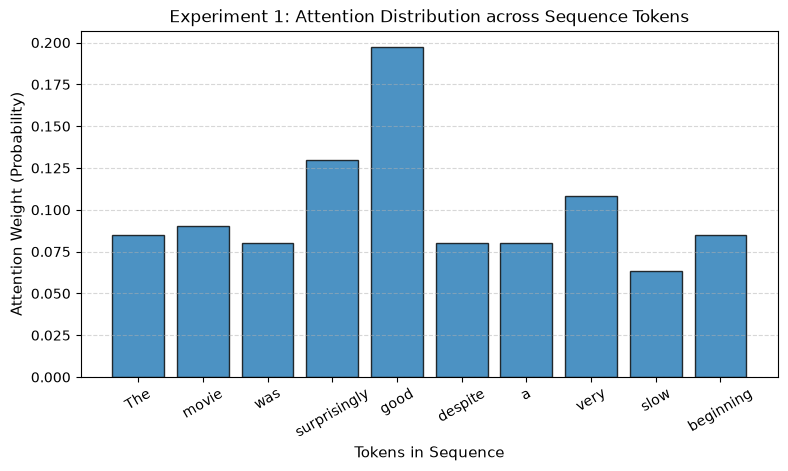

In [6]:
plt.figure(figsize=(9, 4.5))
bars = plt.bar(tokens, attention_weights, color="#1f77b4", edgecolor="black", alpha=0.8)
plt.title("Experiment 1: Attention Distribution across Sequence Tokens", fontsize=12)
plt.xlabel("Tokens in Sequence", fontsize=11)
plt.ylabel("Attention Weight (Probability)", fontsize=11)
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.5)

Nhìn vào bảng số liệu và biểu đồ vừa chạy, điều dễ thấy nhất là trọng số không bị chia đều cho 10 từ. Thay vì mỗi từ nhận 10 phần trăm như nhau, mô hình đã chủ động dồn sự chú ý vào đúng những từ mang nhiều thông tin nhất trong câu.

Từ good nhận được sự chú ý cao nhất với gần 20 phần trăm, theo sau là từ surprisingly với gần 13 phần trăm và very với gần 11 phần trăm. Kết quả này rất khớp với thực tế vì vector query được đặt để tìm kiếm sắc thái cảm xúc, nên những từ thể hiện tính chất và bổ trợ mức độ sẽ ăn khớp mạnh nhất với query và có điểm số cao nhất.

Các từ ngữ pháp phụ như was, despite, a có điểm bằng 0 nên giữ mức sàn khoảng 8 phần trăm. Trong khi đó, từ slow mang nghĩa tiêu cực làm điểm bị âm và nhận tỷ lệ thấp nhất toàn câu với chỉ hơn 6 phần trăm. Điều này chứng minh hàm softmax biết dìm các từ không liên quan xuống nhưng không triệt tiêu chúng về 0 hoàn toàn.

/tmp/ipykernel_705383/2460026463.py:5: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


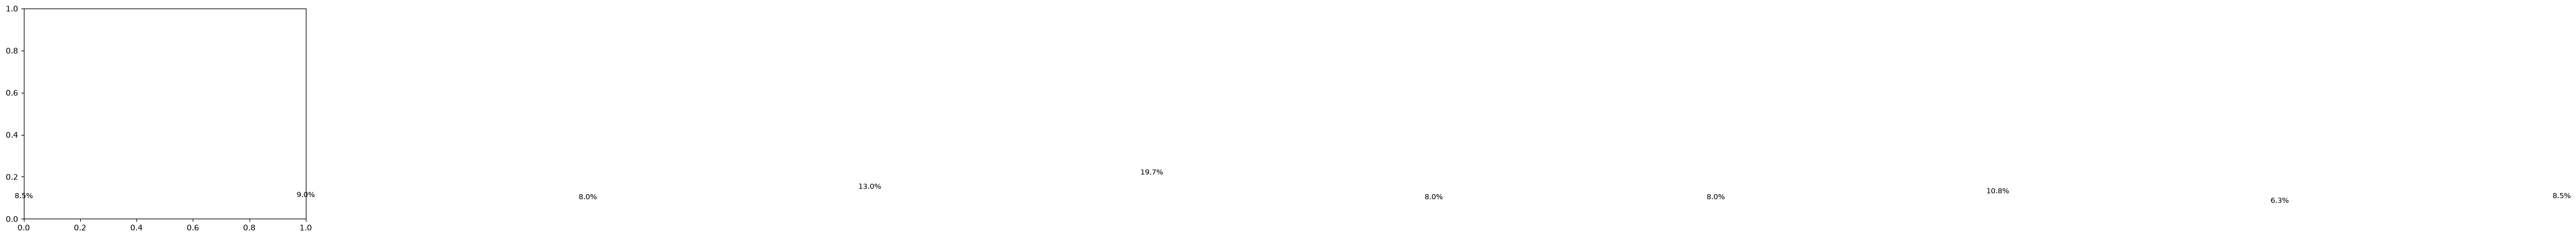

In [7]:
for bar in bars:
    yval = bar.get_height()
    if yval > 0.02:
        plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval*100:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("exp1_attention_distribution.png", dpi=300)
plt.show()